In [29]:
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt

In [6]:
str_url = "https://docs.google.com/spreadsheets/d/e/2PACX-1vRfNroFE_THBtcNXvqGmIjAznHFN7d7J_oaBaUWbuGwCnpifPfAcDWDZJcgRsJ13efcmQu1LcNeXCmq/pub?output=xlsx"

In [41]:
df = pd.read_excel(str_url, sheet_name="Market_Data", index_col="DATE").sort_index()

In [43]:
df.columns.to_list()

['KOSPI',
 'KOSDAQ',
 'DJIA',
 'SPX',
 'CCMP',
 'SPTSX',
 'EUROSTOXX',
 'FTSE',
 'DAX',
 'CAC',
 'NIKKEI',
 'HIS',
 'SHS',
 'WTI',
 'BRENT',
 'XAU',
 'BTC',
 'VIX',
 'DXY',
 'KRWNDF_1M',
 'USDKRW',
 'JPYKRW',
 'EURKRW',
 'CHFKRW',
 'GBPKRW',
 'CADKRW',
 'AUDKRW',
 'NZDKRW',
 'CNYKRW',
 'HKDKRW',
 'IDRKRW',
 'SGDKRW',
 'THBKRW',
 'USDJPY',
 'EURUSD',
 'GBPUSD',
 'USDCHF',
 'USDCAD',
 'AUDUSD',
 'NZDUSD',
 'USDCNH',
 'USDCNY',
 'USDHKD',
 'USDIDR',
 'USDSGD',
 'FED_U',
 'FED_L',
 'BOC',
 'BOJ',
 'BOK',
 'RBA',
 'ECB',
 'BOE',
 'DDEP',
 'CDEP',
 'TDEP_1W',
 'TDEP_1M',
 'TDEP_3M',
 'TDEP_6M',
 'UST_1M',
 'UST_3M',
 'UST_6M',
 'UST_1Y',
 'UST_2Y',
 'UST_3Y',
 'UST_5Y',
 'UST_7Y',
 'UST_10Y',
 'UST_20Y',
 'UST_30Y',
 'KRW_CALL_ON',
 'KTB_3M',
 'KTB_6M',
 'KTB_1Y',
 'KTB_2Y',
 'KTB_3Y',
 'KTB_5Y',
 'KTB_10Y',
 'KTB_20Y',
 'KTB_30Y',
 'MSB_3M',
 'MSB_1Y',
 'MSB_2Y',
 'CD_3M',
 'CP_3M',
 'KORIBOR_1M',
 'KORIBOR_3M',
 'KORIBOR_6M',
 'KORIBOR_12M',
 'IMP_FF_ON',
 'SOFR_ON',
 'SOFR_1M',
 'SOFR_3M'

In [106]:
ktb_cols = ['BOK'] + [col for col in df.columns if 'KTB' in col and 'FRN' not in col]

In [107]:
df_ktb = df[ktb_cols].copy()

In [108]:
df_ktb

,BOK,KTB_3M,KTB_6M,KTB_1Y,KTB_2Y,KTB_3Y,KTB_5Y,KTB_10Y,KTB_20Y,KTB_30Y
DATE,,,,,,,,,,
2019-11-25,1.25,1.253,1.312,1.401,1.448,1.475,1.577,1.725,1.677,1.640
2019-11-26,1.25,1.255,1.314,1.399,1.439,1.475,1.564,1.707,1.658,1.623
2019-11-27,1.25,1.255,1.314,1.390,1.428,1.456,1.528,1.671,1.604,1.567
2019-11-28,1.25,1.255,1.314,1.382,1.408,1.430,1.519,1.667,1.627,1.588
2019-11-29,1.25,1.250,1.307,1.365,1.375,1.385,1.475,1.630,1.595,1.554
...,...,...,...,...,...,...,...,...,...,...
2026-05-11,2.50,2.601,2.701,3.022,3.485,3.598,3.777,3.950,3.939,3.850
2026-05-12,2.50,2.611,2.705,3.066,3.547,3.674,3.870,4.056,4.060,3.971
2026-05-13,2.50,2.611,2.706,3.068,3.507,3.635,3.853,4.044,4.050,3.968


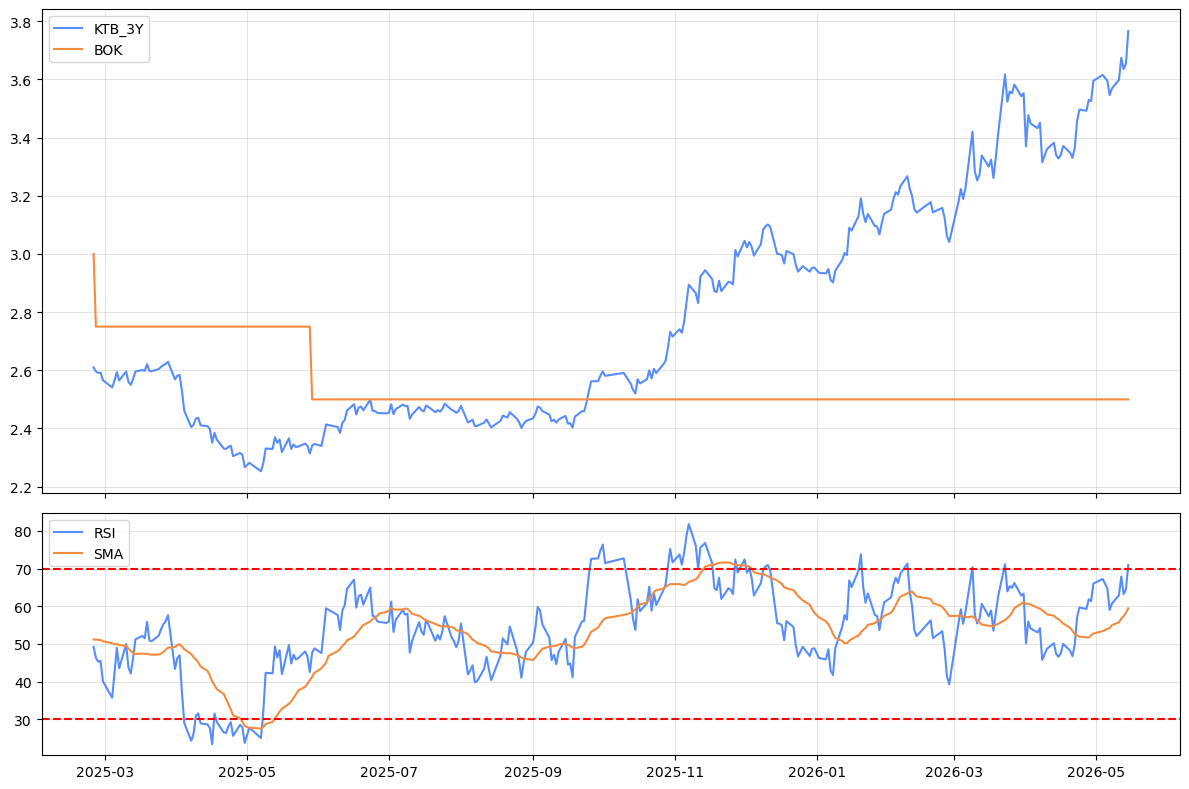

In [114]:
days = 300
ticker = "KTB_3Y"

temp = df_ktb[["BOK", ticker]]
temp["RSI"] = ta.rsi(temp[ticker], length=14)
temp["RSI_SMA"] = ta.sma(temp["RSI"], length=20)
temp = temp.dropna()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), height_ratios=(2, 1), sharex=True)
fig.subplots_adjust(hspace=0.05)

ax1.plot(temp.loc[temp.index[-days]:, ticker], label=ticker)
ax1.plot(temp.loc[temp.index[-days]:, "BOK"], label="BOK")
ax2.plot(temp.loc[temp.index[-days]:, "RSI"], label="RSI")
ax2.plot(temp.loc[temp.index[-days]:, "RSI_SMA"], label="SMA")
ax2.axhline(y=70, color="r", linestyle="--")
ax2.axhline(y=30, color="r", linestyle="--")

ax1.grid()
ax1.legend()
ax2.grid()
ax2.legend()
plt.tight_layout()
plt.show()